# Imports

In [1]:
import os
import json
import torch
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from model import GrokkingSetup

# Configs

In [ ]:
def GetModelFromConfig(path, p=97):
    config_path = os.path.join(path, "config.json")
    with open(config_path, "r") as f:
        config = json.load(f)
        
    model = GrokkingSetup(
        p=p, 
        d_model=config["d_model"], 
        d_k=config["d_k"], 
        d_v=config["d_v"], 
        n_layers=config["n_layers"]
    )
    
    return model

In [ ]:
path = r"experiments/run_L3_D16_20260508_175944"
model = GetModelFromConfig(path)

# 2D PCA

In [35]:
def embedding_analysis_with_pca(model, p=97):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    embeds_2d = PCA(n_components=2).fit_transform(weights)

    df = pd.DataFrame({
        'x': embeds_2d[:, 0],
        'y': embeds_2d[:, 1],
        'token': range(p)
    })
    
    sns.set_theme(palette="rocket")
    plt.figure(figsize=(10, 8))
    
    plot = sns.scatterplot(
        data=df, 
        x='x', 
        y='y', 
        hue='token', 
        legend=False,
        s=100,
        edgecolor='black',
        linewidth=0.5
    )
    
    for i in range(0, p, 5):
        plt.text(
            df.x[i], df.y[i], 
            str(i), fontsize=10, weight='bold', alpha=0.8
        )

    plt.title("PCA For Tokens Embeddings", fontsize=15)
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    
    plt.show()

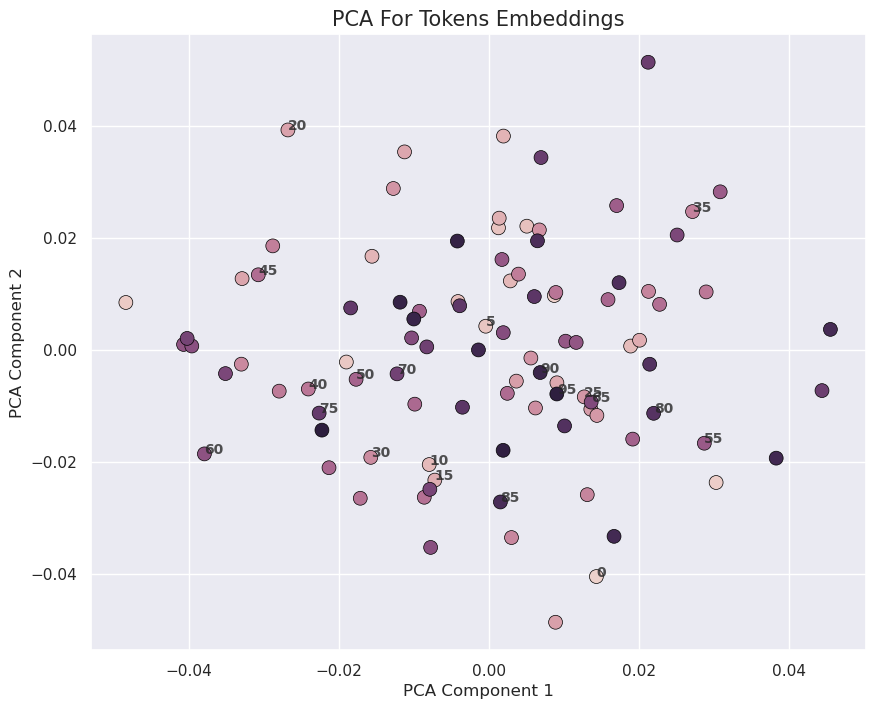

In [11]:
model_path = r"experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_1000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_with_pca(model)

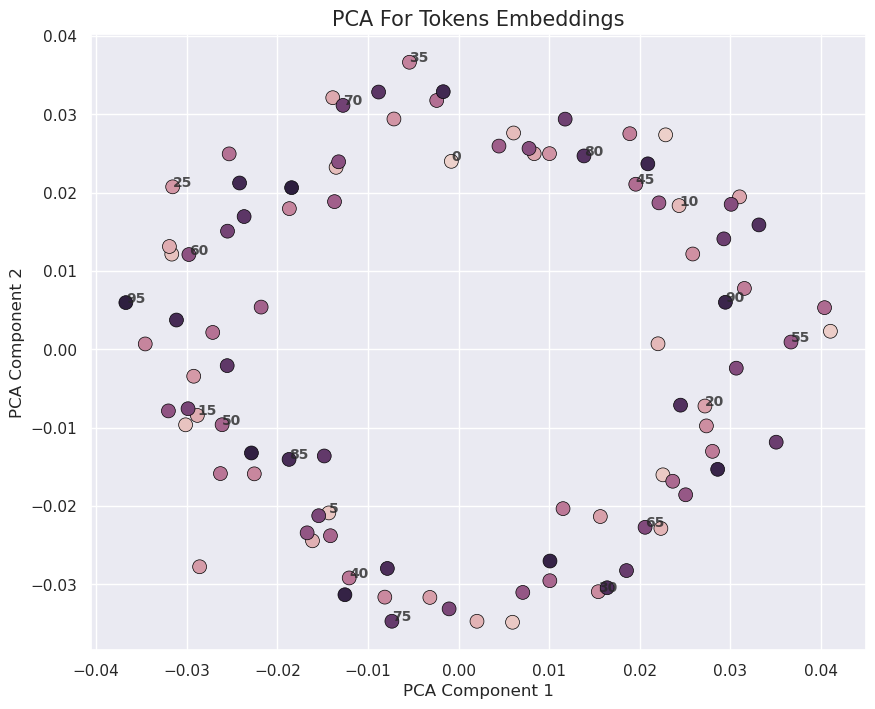

In [12]:
model_path = r"experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_6000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_with_pca(model)

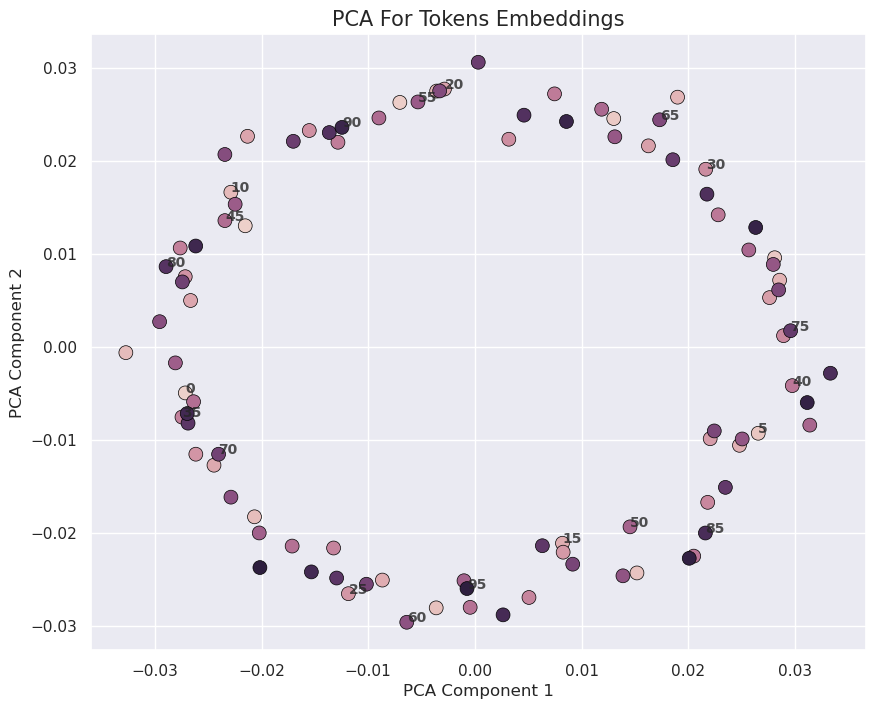

In [13]:
model_path = r"experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_10000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_with_pca(model)

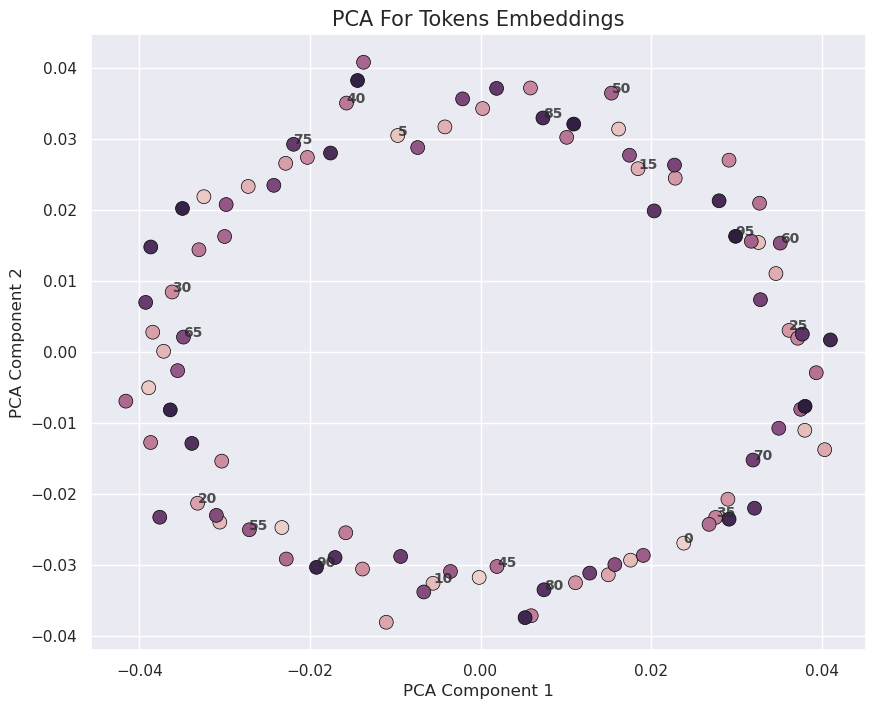

In [15]:
model_path = r"experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_15000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_with_pca(model)

# 2D t-SNE

In [16]:
def embedding_analysis_tsne(model, p=97):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    embeds_2d = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=5).fit_transform(weights)

    df = pd.DataFrame({
        'x': embeds_2d[:, 0],
        'y': embeds_2d[:, 1],
        'token': range(p)
    })
    
    sns.set_theme(palette="rocket")
    plt.figure(figsize=(10, 8))
    
    plot = sns.scatterplot(
        data=df, 
        x='x', 
        y='y', 
        hue='token', 
        legend=False,
        s=100,
        edgecolor='black',
        linewidth=0.5
    )
    
    for i in range(0, p, 5):
        plt.text(
            df.x[i], df.y[i], 
            str(i), fontsize=10, weight='bold', alpha=0.8
        )

    plt.title("t-SNE For Tokens Embeddings", fontsize=15)
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    
    plt.show()

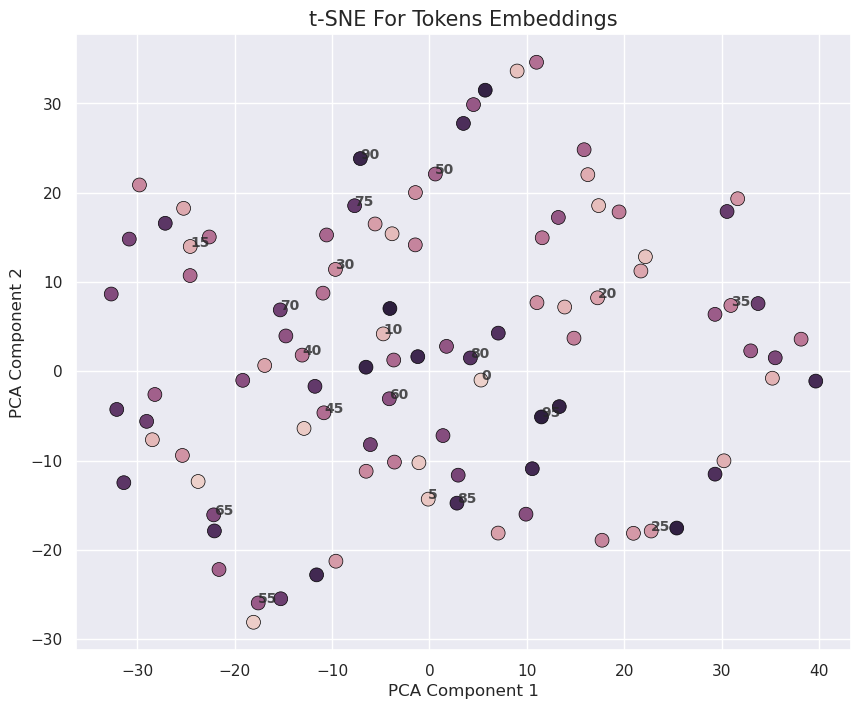

In [19]:
model_path = r"experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_1000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_tsne(model)

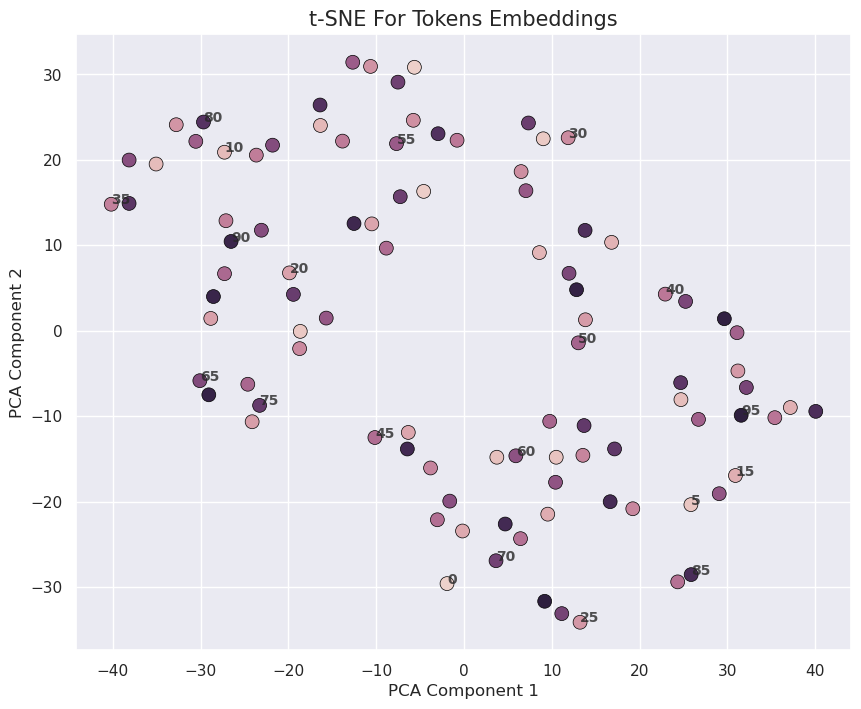

In [21]:
model_path = r"experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_6000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_tsne(model)

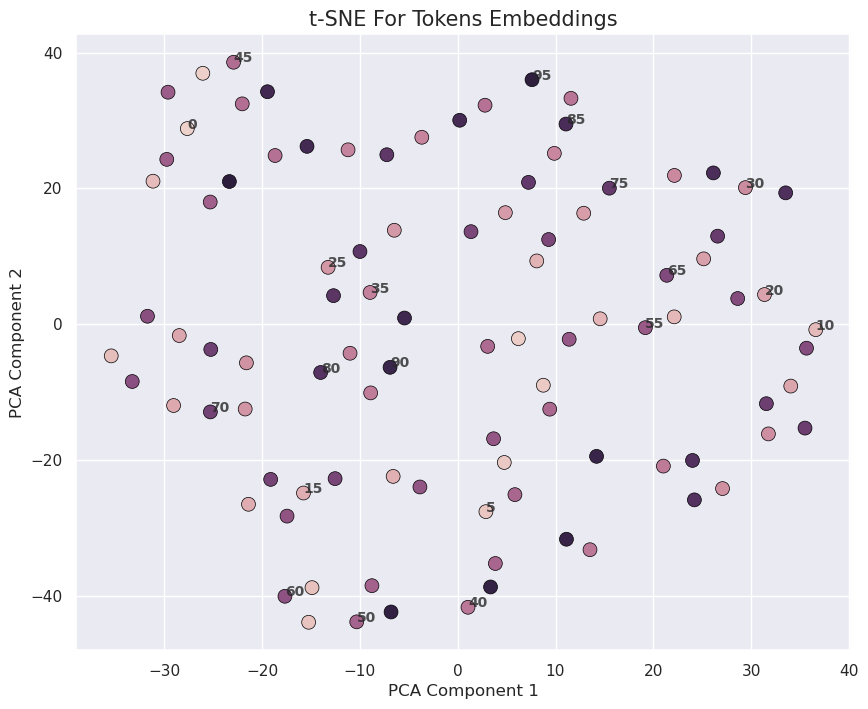

In [28]:
model_path = r"experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_15000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_tsne(model)

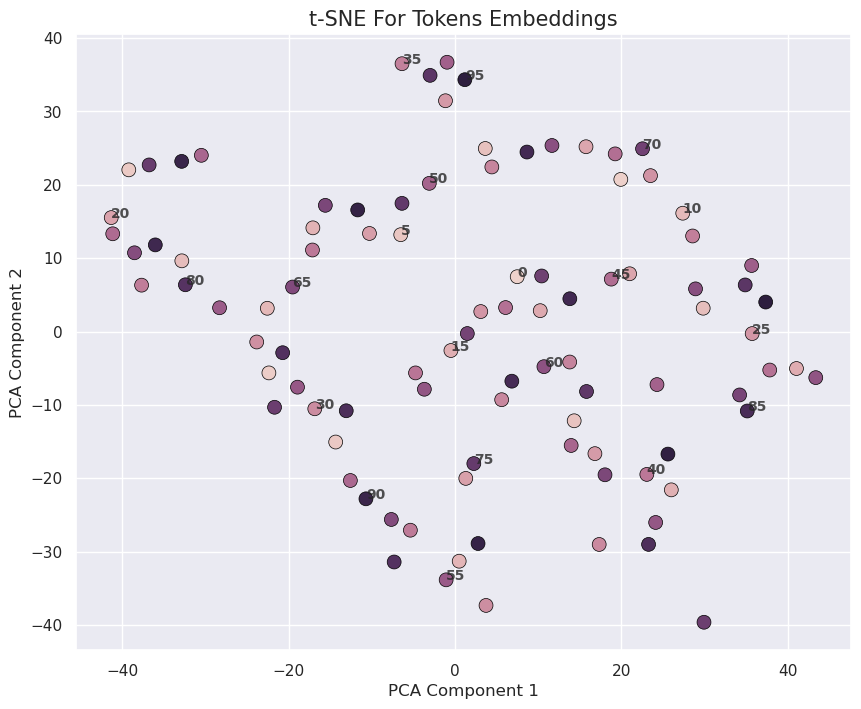

In [32]:
model_path = r"experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_19000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_tsne(model)

# 3D PCA

In [33]:
import plotly.express as px
import pandas as pd
from sklearn.decomposition import PCA

In [34]:
def plot_embeddings_3d(model, p=97, title="3D Token Embeddings PCA"):
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    
    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(weights)
    
    df = pd.DataFrame({
        'PC1': embeds_3d[:, 0],
        'PC2': embeds_3d[:, 1],
        'PC3': embeds_3d[:, 2],
        'token': range(p)
    })
    
    fig = px.scatter_3d(
        df, x='PC1', y='PC2', z='PC3',
        color='token',
        color_continuous_scale=px.colors.sequential.Magenta,
        title=title,
        labels={'token': 'Token Value'},
        opacity=0.8
    )
    
    fig.update_traces(marker=dict(size=5, line=dict(width=1, color='Black')))
    fig.show()

plot_embeddings_3d(model, p=97)

# 3D t-SNE

In [77]:
import pandas as pd
import plotly.express as px
from sklearn.manifold import TSNE

def plot_embeddings_3d_tsne(model, p=97, perplexity=5):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    embeds_3d = TSNE(n_components=3, learning_rate='auto', init='random', perplexity=perplexity).fit_transform(weights)
    

    df = pd.DataFrame({
        'x': embeds_3d[:, 0],
        'y': embeds_3d[:, 1],
        'z': embeds_3d[:, 2],
        'token': range(p)
    })
    
    fig = px.scatter_3d(
        df, x='x', y='y', z='z',
        color='token',
        color_continuous_scale=px.colors.sequential.Magenta,
        title=f"3D t-SNE of Token Embeddings (Perplexity: {perplexity})",
        labels={'token': 'Token Value'},
        opacity=0.8
    )
    
    fig.update_traces(marker=dict(size=5, line=dict(width=1, color='Black')))
    fig.show()


In [80]:
model_path = r"/home/aleczo/Documents/Temp/Research/grokking/research/Power2022/CUDA version/experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_19000.pt"
model.load_state_dict(torch.load(model_path))

plot_embeddings_3d_tsne(model, p=97)

In [ ]:
import numpy as np
import pandas as pd
import torch
import plotly.graph_objects as go
from sklearn.manifold import TSNE

def plot_embeddings_path_3d(model, perplexity, p=97):
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    
    tsne = TSNE(
        n_components=3, 
        perplexity=perplexity, 
        random_state=42, 
        init='pca', 
        learning_rate='auto'
    )
    embeds_3d = tsne.fit_transform(weights)
    
    path_indices = list(range(p)) + [0]
    path_coords = embeds_3d[path_indices]
    
    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=path_coords[:, 0],
        y=path_coords[:, 1],
        z=path_coords[:, 2],
        mode='lines',
        line=dict(color='rgba(100, 100, 100, 0.5)', width=3),
        name='Path (Sequence)',
        hoverinfo='none'
    ))

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        marker=dict(
            size=5,
            color=list(range(p)),
            colorscale='magenta',
            opacity=0.9,
            line=dict(color='black', width=1)
        ),
        text=[f"{i}" for i in range(p)],
        hoverinfo='text',
        name='Tokens'
    ))

    fig.update_layout(
        title=f"3D t-SNE Path: Token Embeddings Sequence (p={p})",
        scene=dict(
            xaxis_title='t-SNE 1',
            yaxis_title='t-SNE 2',
            zaxis_title='t-SNE 3'
        ),
        margin=dict(l=0, r=0, b=0, t=40),
        showlegend=False
    )
    
    fig.show()

In [82]:
plot_embeddings_path_3d(model, perplexity=7, p=97)

In [66]:
def embedding_analysis_tsne_2d_path(model, p=97):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    tsne = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=8)
    embeds_2d = tsne.fit_transform(weights)

    df = pd.DataFrame({
        'x': embeds_2d[:, 0],
        'y': embeds_2d[:, 1],
        'token': range(p)
    })
    
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(12, 9))
    
    path_indices = list(range(p)) + [0]
    
    plt.plot(df.x.iloc[path_indices], df.y.iloc[path_indices], 
            color='gray', alpha=0.4, linestyle='-', linewidth=1.5, zorder=1)
    
    plot = sns.scatterplot(
        data=df, 
        x='x', 
        y='y', 
        hue='token', 
        legend=False,
        s=100,
        edgecolor='black',
        linewidth=0.5
    )
    

    for i in range(0, p, 5):
        plt.text(
            df.x[i] + 0.3, df.y[i] + 0.3, 
            str(i), fontsize=11, weight='bold', alpha=0.9, zorder=3
        )

    plt.title("2D t-SNE Path: Token Embeddings Sequential Progress", fontsize=15)
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    
    plt.show()

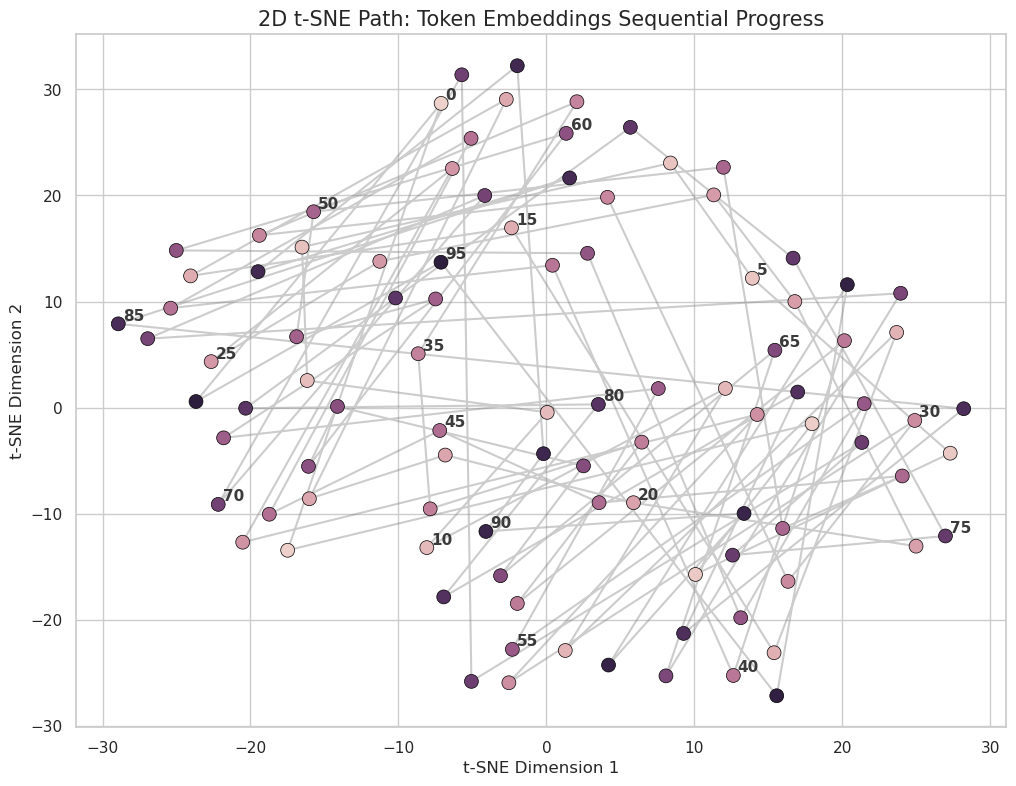

In [76]:
embedding_analysis_tsne_2d_path(model)